In [26]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats

# Vitis Data Analysis

In [ ]:
# Load data
df_vitis_gpt_41_mini_k10 = pd.read_csv('vitis_gpt-4.1-mini_k10.csv')

# Function to calculate pass@k rate for Csim only
def calculate_csim_pass_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for Csim only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for Csim
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['status']:
            if isinstance(status, str) and 'passed' in status.lower():
                passed = True
                break
            elif str(status) == 'Passed Csim':
                passed = True
                break
        
        results.append(passed)
    
    return sum(results) / len(results) if results else 0

# Function to calculate pass@k rate for C synthesis
def calculate_synth_pass_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for synthesis - what fraction of kernels have at least one solution
    in iterations/attempts 1 through k that both passed status and has no synthesis errors
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for synthesis
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        # If there's no data for this kernel within iterations/attempts 1-k, consider it a fail
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed both criteria
        passed = False
        for _, row in kernel_subset.iterrows():
            status_pass = False
            synth_pass = False
            
            # Check status column
            if isinstance(row['status'], str) and 'passed' in row['status'].lower():
                status_pass = True
            elif str(row['status']) == 'Passed Csim':  # Or whatever exact string indicates success
                status_pass = True
                
            # Check synth_errors column
            if row['synth_errors'] == '-':
                synth_pass = True
                
            # Both conditions must be met
            if status_pass and synth_pass:
                passed = True
                break
        
        results.append(passed)
    
    # Return the fraction of kernels that passed
    return sum(results) / len(results) if results else 0




def calculate_has_dot_at_k(df, k_value=1, a_value=1, iteration_column='iteration', iteration_col2="attempt"):
    """
    Calculate the pass@k rate for HasDot only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for hasDot
    """
    final_results = []
    for k in range(1, k_value+1):
        for a in range(a_value):
            results = []

            for kernel in df['kernel'].unique():
                kernel_data = df[df['kernel'] == kernel]
                
                # Filter to only include iterations/attempts 1 through k
                kernel_subset = kernel_data[kernel_data[iteration_column] <= k]
                kernel_subset = kernel_subset[kernel_subset[iteration_col2] <= a]
                # print(kernel_subset)
                if len(kernel_subset) == 0:
                    results.append(False)
                    continue

                # Check if any iteration/attempt from 1 to k passed Csim
                passed = False
                for status in kernel_subset['has_dot']:
                    if status:
                        passed = True
                        break
                    elif str(status) == 'TRUE':
                        passed = True
                        break

                results.append(passed)
                
            final_results.append(sum(results) / len(results) if results else 0)

    return final_results

# Function to calculate pass@k rate for Csim only
def calculate_has_dcp_at_k(df, k_value=1, a_value=1, iteration_column='iteration', iteration_col2="attempt"):
    """
    Calculate the pass@k rate for dcp only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for dcp
    """
    final_results = []
    for k in range(1, k_value+1):
        for a in range(a_value):
            results = []
            for kernel in df['kernel'].unique():
                kernel_data = df[df['kernel'] == kernel]
                
                # Filter to only include iterations/attempts 1 through k
                kernel_subset = kernel_data[kernel_data[iteration_column] <= k]
                kernel_subset = kernel_subset[kernel_subset[iteration_col2] <= a]
                if len(kernel_subset) == 0:
                    results.append(False)
                    continue

                # Check if any iteration/attempt from 1 to k passed Csim
                passed = False
                for status in kernel_subset['has_dcp']:
                    if status:
                        passed = True
                        break
                    elif str(status) == 'TRUE':
                        passed = True
                        break

                results.append(passed)

            final_results.append(sum(results) / len(results) if results else 0)

    return final_results

: 

: 

## Helper Function to Calculate Pass@k

In [ ]:
def is_number(s):
    try:
        float(s)
        return True
    except ValueError:
        return False


def calculate_pass_at_k(df, k_value=1, a_value=1, iter_col1='iteration', iter_col2="attempts", meas="csim", model="gpt-4.1-mini"):
    """
    Calculate the pass@k for whatever measurement you are interested in.
    
    Paremeters:
    df (Dataframe)
    k value: how many passes.
    a value: how many attempts
    iter_col1 which column to look at for k values
    iter_col2 which column to look at for attempts
    meas what you are measuring ("csim", "csynth", '"dot"', "dcp")
    """

    #map to map the measurement values to the corresponding column
    map = {
        "csim": {
            "col": "status",
            "pass": "passed",
            "pass2": "success"
        },
        "csynth": {
            "col": "synth_errors",
            "pass": "-",
            "pass2": "numerical"
        },
        "dot": {
            "col": "has_dot",
            "pass": "true"
        },
        "dcp": {
            "col": "has_dcp",
            "pass": "true"
        }
    }

    
    final_results = []
    for k in range(k_value,k_value+1):
        for a in range(0, a_value) if (meas == "dot" or meas == "dcp") else range(1, a_value+1):
            results = []
            for kernel in df['kernel'].unique():
                kernel_data = df[df['kernel'] == kernel]
                kernel_data = kernel_data[kernel_data['model'].str.contains(model)]

                # Create a subset with the unique kernel and only up to the attempt and k value we are on
                data_subset = kernel_data[kernel_data[iter_col1] <= k]
                data_subset = data_subset[data_subset[iter_col2] <= a]
                # print(data_subset)
                if len(data_subset) == 0:
                    results.append(False)
                    continue
                    
                if meas == "csynth":
                    col1 = "synth_errors"
                    col2 = "latency"
                    pass_value1 = "-"
                    passed = False
                    for error, latency in zip(data_subset[col1], data_subset[col2]):

                        has_latency = True
                        try: 
                            int(latency)
                        except ValueError:
                            has_latency = False
                        if str(error) == pass_value1 and has_latency:
                            passed = True
                            break
                    results.append(passed)


                else:
                    col_name = map[meas]["col"]
                    pass_value = map[meas]["pass"]
                    passed = False
                    for status in data_subset[col_name]:
                        # print(f"Actual: {status} Expected: {pass_value}")

                        if str(status).lower() == pass_value:
                            passed = True
                            break
                    results.append(passed)

            final_results.append(sum(results) / len(results) if results else 0)
    return final_results
                

        




: 

: 

## Vitis 101 kernels, k=3 n=3 gpt4.1-mini

### CSIM with the 3 k passes

[0.7128712871287128, 0.8613861386138614, 0.8811881188118812]
[0.7821782178217822, 0.9108910891089109, 0.9405940594059405]
[0.801980198019802, 0.9207920792079208, 0.9405940594059405]


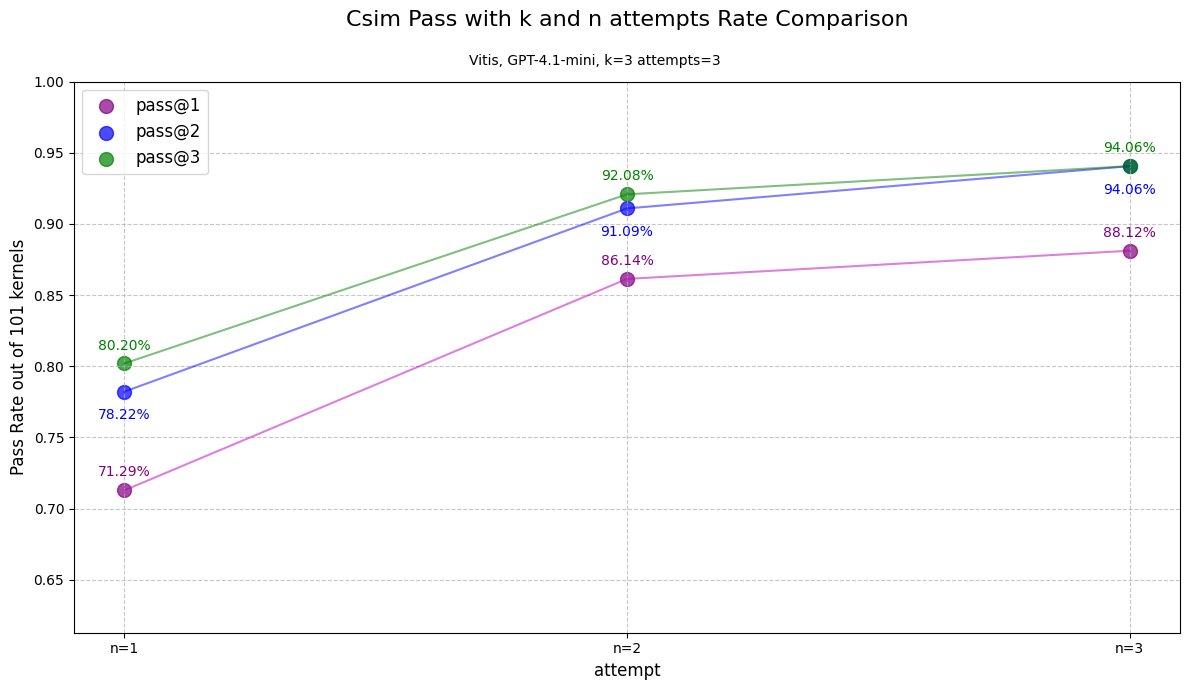

: 

: 

In [ ]:
df_vitis_gpt_41mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')



attempt_values = 3
k_values = 1
total_values = attempt_values * k_values
x_values = ["n=1","n=2","n=3"]


csim_pass_1 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=1, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csim_pass_2 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=2, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csim_pass_3 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")


print(csim_pass_1)
print(csim_pass_2)
print(csim_pass_3)

# csynth_passes = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(x_values, csim_pass_1, s=100, color='purple', alpha=0.7, label='pass@1')
ax.scatter(x_values, csim_pass_2, s=100, color='blue', alpha=0.7, label='pass@2')
ax.scatter(x_values, csim_pass_3, s=100, color='green', alpha=0.7, label='pass@3')


# Add lines connecting the points
ax.plot(x_values, csim_pass_1, 'm-', alpha=0.5)
ax.plot(x_values, csim_pass_2, 'b-', alpha=0.5)
ax.plot(x_values, csim_pass_3, 'g-', alpha=0.5)


# Add labels for each point
for k, rate in zip(x_values, csim_pass_1):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(x_values, csim_pass_2):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')
    
for k, rate in zip(x_values, csim_pass_3):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='green')

# Customize the plot
ax.set_xlabel('attempt', fontsize=12)
ax.set_ylabel('Pass Rate out of 101 kernels', fontsize=12)
ax.set_title('Csim Pass with k and n attempts Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(x_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_pass_1) if csim_pass_1 else 0, 
               max(csim_pass_2) if csim_pass_2 else 0,
               max(csim_pass_3) if csim_pass_3 else 0)
min_rate = min(min(csim_pass_1) if csim_pass_1 else .5, 
               min(csim_pass_2) if csim_pass_2 else .5,
               min(csim_pass_3) if csim_pass_3 else .5)

ax.set_ylim(max(0.5, min_rate - 0.1), min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis, GPT-4.1-mini, k=3 attempts=3', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### CSYNTH With the 3 K Passes

[0.22772277227722773, 0.6534653465346535, 0.7524752475247525]
[0.44554455445544555, 0.7722772277227723, 0.8415841584158416]
[0.5742574257425742, 0.801980198019802, 0.8712871287128713]


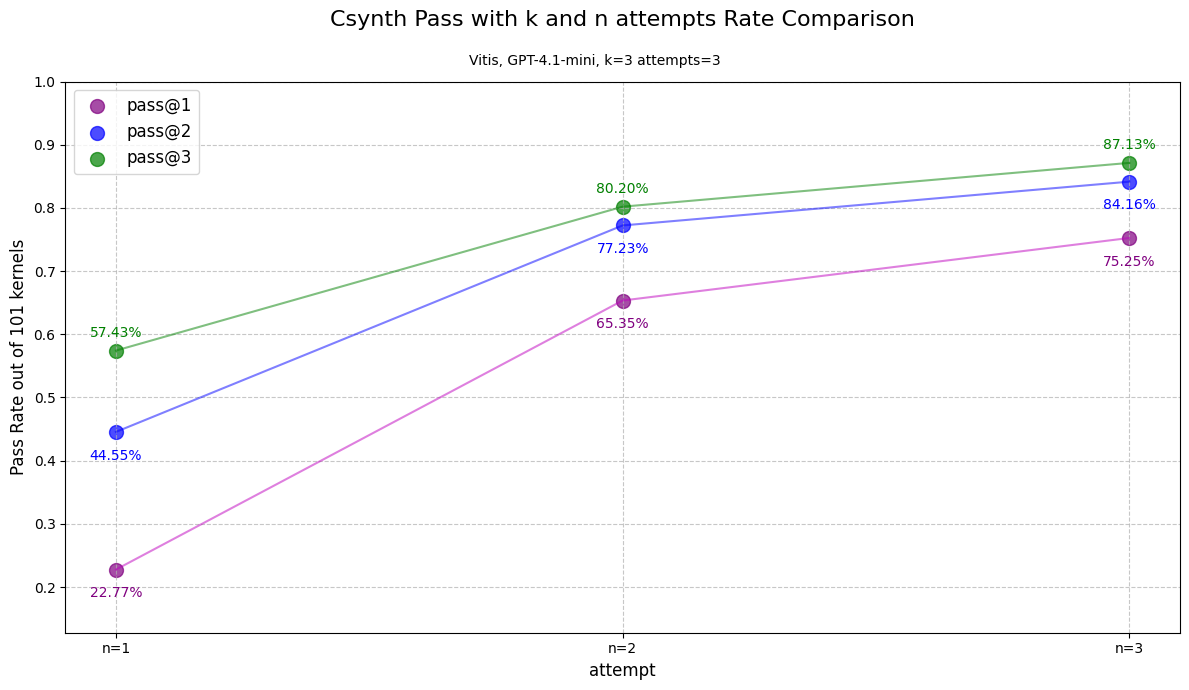

: 

: 

In [ ]:
df_vitis_gpt_41mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')



attempt_values = 3
k_values = 1
total_values = attempt_values * k_values
x_values = ["n=1","n=2","n=3"]

csynth_pass_1 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=1, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
csynth_pass_2 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=2, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
csynth_pass_3 = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
print(csynth_pass_1)
print(csynth_pass_2)
print(csynth_pass_3)

# csynth_passes = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(x_values, csynth_pass_1, s=100, color='purple', alpha=0.7, label='pass@1')
ax.scatter(x_values, csynth_pass_2, s=100, color='blue', alpha=0.7, label='pass@2')
ax.scatter(x_values, csynth_pass_3, s=100, color='green', alpha=0.7, label='pass@3')


# Add lines connecting the points
ax.plot(x_values, csynth_pass_1, 'm-', alpha=0.5)
ax.plot(x_values, csynth_pass_2, 'b-', alpha=0.5)
ax.plot(x_values, csynth_pass_3, 'g-', alpha=0.5)


# Add labels for each point
for k, rate in zip(x_values, csynth_pass_1):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='purple')

for k, rate in zip(x_values, csynth_pass_2):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

for k, rate in zip(x_values, csynth_pass_3):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='green')

# Customize the plot
ax.set_xlabel('attempt', fontsize=12)
ax.set_ylabel('Pass Rate out of 101 kernels', fontsize=12)
ax.set_title('Csynth Pass with k and n attempts Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(x_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csynth_pass_1) if csynth_pass_1 else 0, 
               max(csynth_pass_2) if csynth_pass_2 else 0,
               max(csynth_pass_3) if csynth_pass_3 else 0)
min_rate = min(min(csynth_pass_1) if csynth_pass_1 else .5, 
               min(csynth_pass_2) if csynth_pass_2 else .5,
               min(csynth_pass_3) if csynth_pass_3 else .5)

ax.set_ylim(min(0.5, min_rate - 0.1), min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis, GPT-4.1-mini, k=3 attempts=3', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### CSim and CSynth without Separation K=3 Attempts=3

9
3
[0.801980198019802, 0.9207920792079208, 0.9405940594059405]
3
[0.5742574257425742, 0.801980198019802, 0.8712871287128713]


ValueError: x and y must be the same size

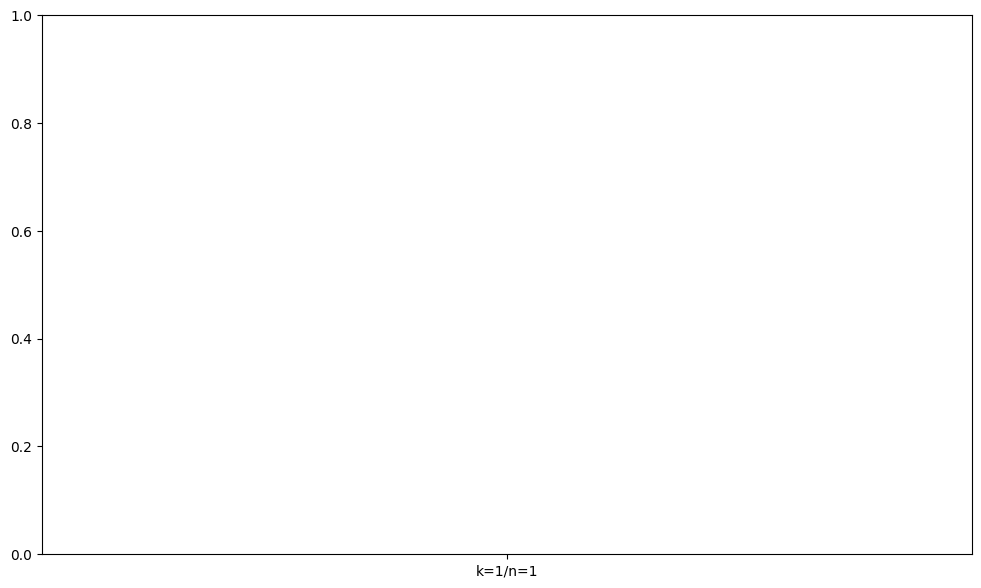

: 

: 

In [ ]:
df_vitis_gpt_41mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')




attempt_values = 3
k_values = 3
total_values = attempt_values * k_values
x_values = ["k=1/n=1", "k=1/n=2","k=1/n=3","k=2/n=1","k=2/n=2","k=2/n=3","k=3/n=1","k=3/n=2","k=3/n=3"]
csim_pass_rates = []
csynth_pass_rates = []


csim_rates = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csynth_rates = calculate_pass_at_k(df_vitis_gpt_41mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")

print(len(x_values))
print(len(csim_rates))
print(csim_rates)
print(len(csynth_rates))
print(csynth_rates)
# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(x_values, csim_rates, s=100, color='purple', alpha=0.7, label='csim Pass with n Attempts')
ax.scatter(x_values, csynth_rates, s=100, color='blue', alpha=0.7, label='csynth Pass with n Attempts')

# Add lines connecting the points
ax.plot(x_values, csim_rates, 'm-', alpha=0.5)
ax.plot(x_values, csynth_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(x_values, csim_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(x_values, csynth_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('k / attempt', fontsize=12)
ax.set_ylabel('Pass Rate', fontsize=12)
ax.set_title('csim vs csynth generation Pass with k and n attempts Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(x_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_rates) if csim_rates else 0, 
               max(csynth_rates) if csynth_rates else 0)
ax.set_ylim(0, min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Dynarapid, GPT-4.1-mini, k=3 attempts=3', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


: 

: 

### Dynarapid Run pass@10

[83.33333333]
[66.66666667]


ValueError: x and y must be the same size

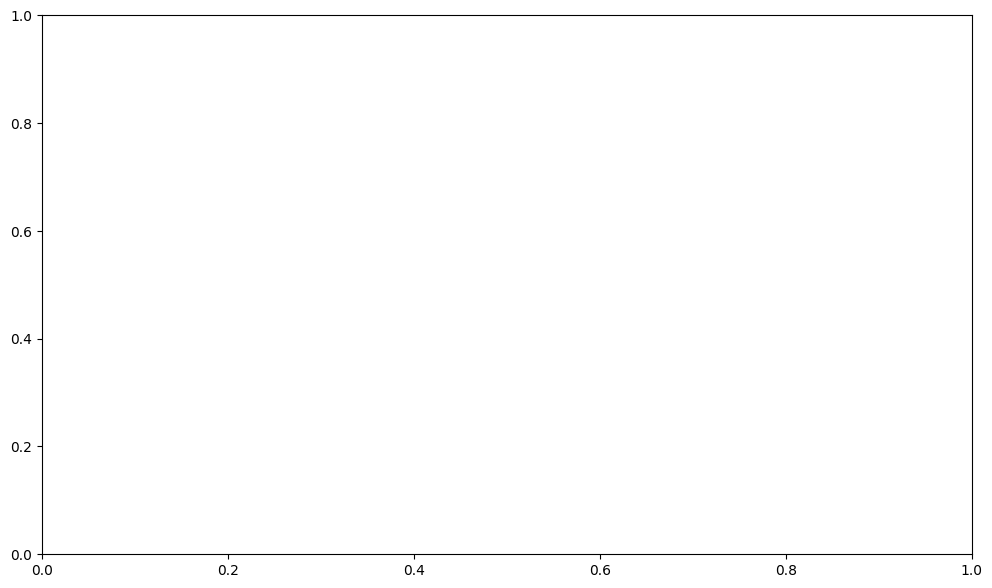

: 

: 

In [ ]:
df_dynarapid_gpt_41_mini_k10 = pd.read_csv('dynarapid_gpt-4.1-mini_k10.csv')


# HasDot and HasDCP
k_values = range(1, 11)



dot_rates = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k10, k_value=10, a_value=1, iter_col1="pass@k", iter_col2="attempt", meas="dot")
dcp_rates = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k10, k_value=10, a_value=1, iter_col1="pass@k", iter_col2="attempt", meas="dcp")

dot_rates = np.array(dot_rates)*100
dcp_rates = np.array(dcp_rates)*100
print(dot_rates)
print(dcp_rates)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(k_values, dot_rates, s=100, color='purple', alpha=0.7, label='C Synthesis')
ax.scatter(k_values, dcp_rates, s=100, color='blue', alpha=0.7, label='Place and Route Implementation')



# Add lines connecting the points
ax.plot(k_values, dot_rates, 'm-', alpha=0.5)
ax.plot(k_values, dcp_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, dot_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(k_values, dcp_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('Pass@k value', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Synthesis and Place and Route Implementation Pass@k Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(dot_rates) if dot_rates.any() else 0, 
               max(dcp_rates) if dcp_rates.any() else 0)
ax.set_ylim(0, min(100.0, max_rate * 1.20))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Dynarapid, GPT-4.1-mini, 30 Kernels, pass@1-pass@10, No Feedback', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### Dynamatic k=1 attempts=10

[83.33333333 83.33333333 86.66666667 86.66666667 86.66666667 86.66666667
 86.66666667 86.66666667 86.66666667 86.66666667]
[60.         70.         76.66666667 83.33333333 83.33333333 83.33333333
 83.33333333 83.33333333 83.33333333 83.33333333]


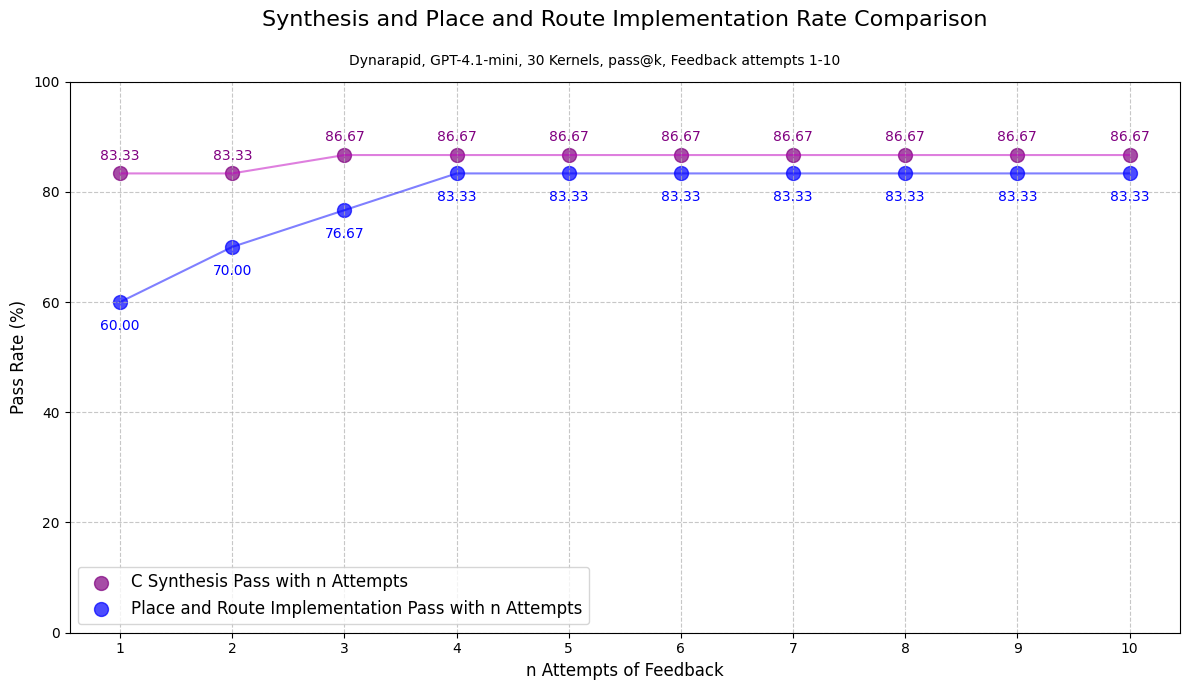

: 

: 

In [ ]:
# HasDot and HasDCP
df_dynarapid_gpt_41_mini_k1_a10 = pd.read_csv('dynarapid_gpt-4.1-mini_k1_attempts10.csv')

attempt_values = range(1, 11)


dot_rates = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k1_a10, k_value=1, a_value=10, iter_col1="pass@k", iter_col2="attempt", meas="dot")
dcp_rates = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k1_a10, k_value=1, a_value=10, iter_col1="pass@k", iter_col2="attempt", meas="dcp")

dot_rates = np.array(dot_rates)*100
dcp_rates = np.array(dcp_rates)*100
print(dot_rates)
print(dcp_rates)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(attempt_values, dot_rates, s=100, color='purple', alpha=0.7, label='C Synthesis Pass with n Attempts')
ax.scatter(attempt_values, dcp_rates, s=100, color='blue', alpha=0.7, label='Place and Route Implementation Pass with n Attempts')

# Add lines connecting the points
ax.plot(attempt_values, dot_rates, 'm-', alpha=0.5)
ax.plot(attempt_values, dcp_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(attempt_values, dot_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(attempt_values, dcp_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('n Attempts of Feedback', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Synthesis and Place and Route Implementation Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(attempt_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(dot_rates) if dot_rates.any() else 0, 
               max(dcp_rates) if dcp_rates.any() else 0)
ax.set_ylim(0, min(100.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Dynarapid, GPT-4.1-mini, 30 Kernels, pass@k, Feedback attempts 1-10', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### Dynarapid k=3 attempts=3

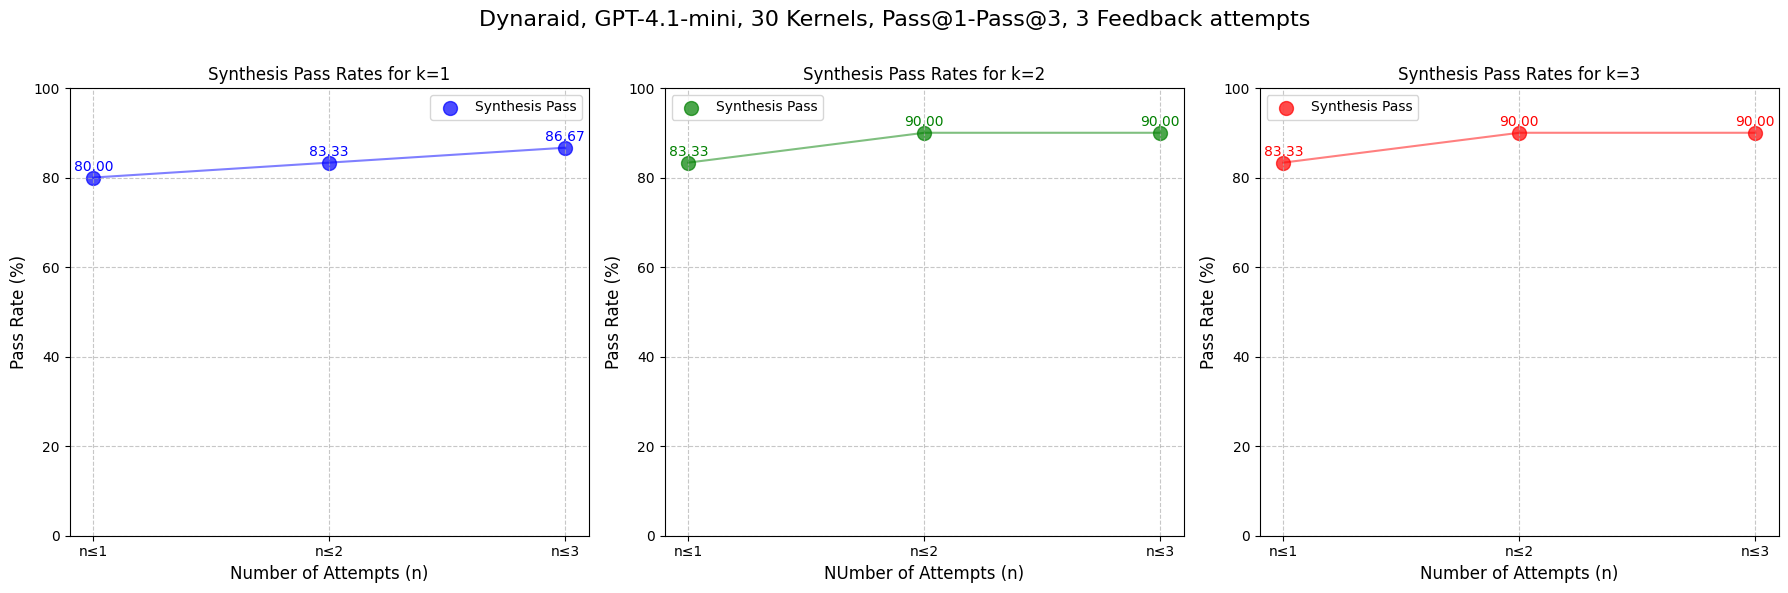

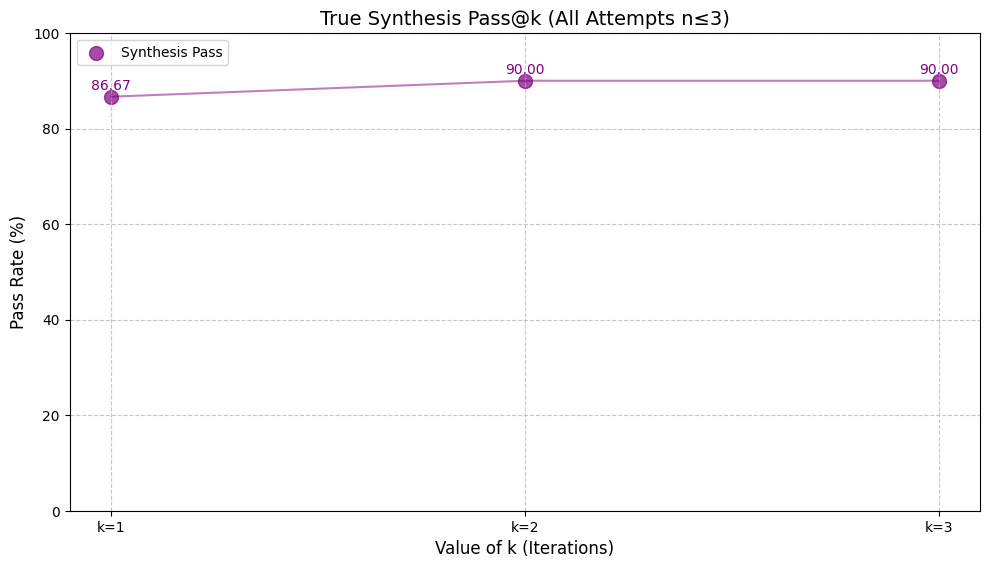

: 

: 

In [ ]:

# Load the data
df_vitis_gpt_41_mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')

df_dynarapid_gpt_41_mini_k3_a3 = pd.read_csv('dynarapid_gpt-4.1-mini_k3_attempts3.csv')


dot_rates_k1 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=1, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")
dot_rates_k2 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=2, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")
dot_rates_k3 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=3, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")

dot_rates_k1 = np.array(dot_rates_k1) * 100
dot_rates_k2 = np.array(dot_rates_k2) * 100
dot_rates_k3 = np.array(dot_rates_k3) * 100

# ----- First figure: Three subplots for k=1,2,3 -----
fig1, axes = plt.subplots(1, 3, figsize=(18, 6))

# Common x-axis labels
n_values = [1, 2, 3]
x_labels = [f"n≤{n}" for n in n_values]

# Plot for k=1
ax = axes[0]
ax.scatter(x_labels, dot_rates_k1, s=100, color='blue', alpha=0.7, label='Synthesis Pass')
ax.plot(x_labels, dot_rates_k1, 'b-', alpha=0.5)
for i, rate in enumerate(dot_rates_k1):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='blue')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Synthesis Pass Rates for k=1', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=2
ax = axes[1]
ax.scatter(x_labels, dot_rates_k2, s=100, color='green', alpha=0.7, label='Synthesis Pass')
ax.plot(x_labels, dot_rates_k2, 'g-', alpha=0.5)
for i, rate in enumerate(dot_rates_k2):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='green')
ax.set_xlabel('NUmber of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Synthesis Pass Rates for k=2', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=3
ax = axes[2]
ax.scatter(x_labels, dot_rates_k3, s=100, color='red', alpha=0.7, label='Synthesis Pass')
ax.plot(x_labels, dot_rates_k3, 'r-', alpha=0.5)
for i, rate in enumerate(dot_rates_k3):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='red')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Synthesis Pass Rates for k=3', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Add a title for the first figure
fig1.suptitle('Dynaraid, GPT-4.1-mini, 30 Kernels, Pass@1-Pass@3, 3 Feedback attempts', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Make room for the suptitle

# ----- Second figure: True pass@k -----
fig2, ax = plt.subplots(figsize=(10, 6))

k_values = [1, 2, 3]
x_labels = [f"k={k}" for k in k_values]

true_pass_at_k_rates = [dot_rates_k1[-1], dot_rates_k2[-1], dot_rates_k3[-1]]

# Plot data for the true pass@k comparison
ax.scatter(x_labels, true_pass_at_k_rates, s=100, color='purple', alpha=0.7, label='Synthesis Pass')
ax.plot(x_labels, true_pass_at_k_rates, 'purple', alpha=0.5)

# Add labels for each point
for i, rate in enumerate(true_pass_at_k_rates):
    ax.annotate(f'{rate:.2F}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='purple')

# Customize plot
ax.set_xlabel('Value of k (Iterations)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('True Synthesis Pass@k (All Attempts n≤3)', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# fig2.suptitle('Vitis, GPT-4.1-mini, True CSynth Pass@k Comparison', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.9)  # Make room for the suptitle

# Display all figures
plt.show()
 

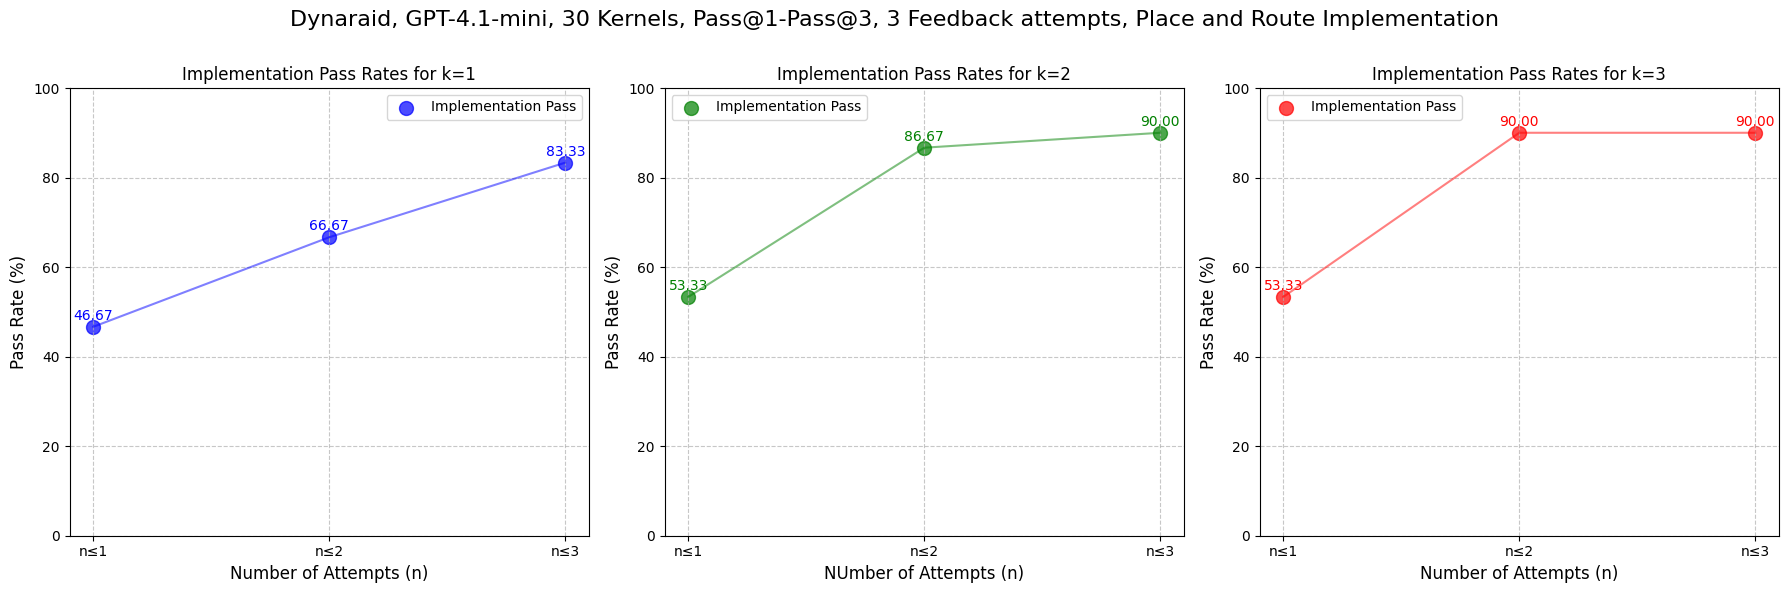

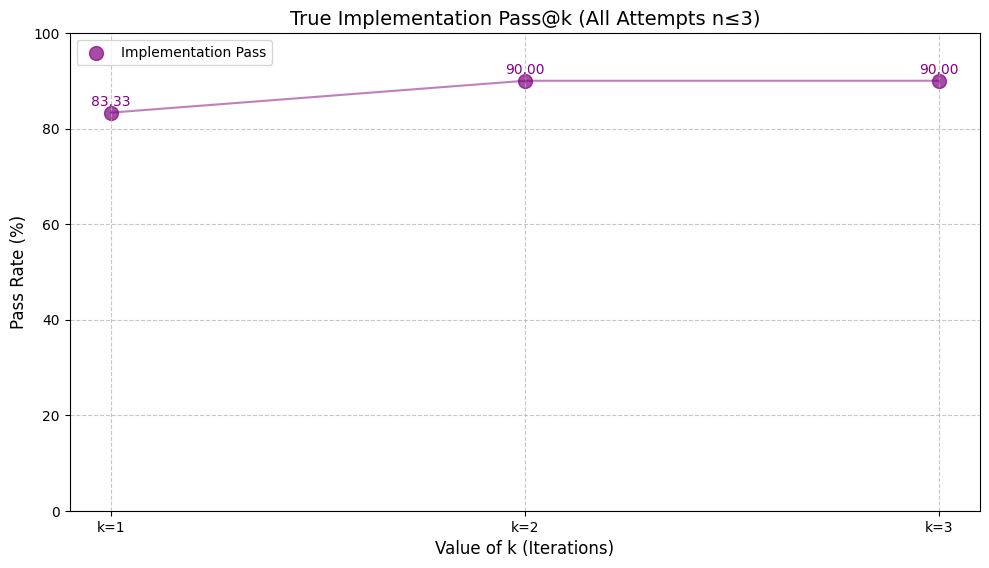

: 

: 

In [ ]:

# Load the data
df_vitis_gpt_41_mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')

df_dynarapid_gpt_41_mini_k3_a3 = pd.read_csv('dynarapid_gpt-4.1-mini_k3_attempts3.csv')


# dot_rates_k1 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=1, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")
# dot_rates_k2 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=2, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")
# dot_rates_k3 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=3, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dot")

# print(dot_rates_k1)

dcp_rates_k1 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=1, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dcp")
dcp_rates_k2 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=2, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dcp")
dcp_rates_k3 = calculate_pass_at_k(df_dynarapid_gpt_41_mini_k3_a3, k_value=3, a_value=3, iter_col1="pass@k", iter_col2="attempt", meas="dcp")

dcp_rates_k1 = np.array(dcp_rates_k1) * 100
dcp_rates_k2 = np.array(dcp_rates_k2) * 100
dcp_rates_k3 = np.array(dcp_rates_k3) * 100


# ----- First figure: Three subplots for k=1,2,3 -----
fig1, axes = plt.subplots(1, 3, figsize=(18, 6))

# Common x-axis labels
n_values = [1, 2, 3]
x_labels = [f"n≤{n}" for n in n_values]

# Plot for k=1
ax = axes[0]
ax.scatter(x_labels, dcp_rates_k1, s=100, color='blue', alpha=0.7, label='Implementation Pass')
ax.plot(x_labels, dcp_rates_k1, 'b-', alpha=0.5)
for i, rate in enumerate(dcp_rates_k1):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='blue')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Implementation Pass Rates for k=1', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=2
ax = axes[1]
ax.scatter(x_labels, dcp_rates_k2, s=100, color='green', alpha=0.7, label='Implementation Pass')
ax.plot(x_labels, dcp_rates_k2, 'g-', alpha=0.5)
for i, rate in enumerate(dcp_rates_k2):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='green')
ax.set_xlabel('NUmber of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Implementation Pass Rates for k=2', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=3
ax = axes[2]
ax.scatter(x_labels, dcp_rates_k3, s=100, color='red', alpha=0.7, label='Implementation Pass')
ax.plot(x_labels, dcp_rates_k3, 'r-', alpha=0.5)
for i, rate in enumerate(dcp_rates_k3):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='red')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Implementation Pass Rates for k=3', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Add a title for the first figure

fig1.suptitle('Dynaraid, GPT-4.1-mini, 30 Kernels, Pass@1-Pass@3, 3 Feedback attempts, Place and Route Implementation', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Make room for the suptitle

# ----- Second figure: True pass@k -----
fig2, ax = plt.subplots(figsize=(10, 6))

k_values = [1, 2, 3]
x_labels = [f"k={k}" for k in k_values]

true_pass_at_k_rates = [dcp_rates_k1[-1], dcp_rates_k2[-1], dcp_rates_k3[-1]]

# Plot data for the true pass@k comparison
ax.scatter(x_labels, true_pass_at_k_rates, s=100, color='purple', alpha=0.7, label='Implementation Pass')
ax.plot(x_labels, true_pass_at_k_rates, 'purple', alpha=0.5)

# Add labels for each point
for i, rate in enumerate(true_pass_at_k_rates):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='purple')

# Customize plot
ax.set_xlabel('Value of k (Iterations)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('True Implementation Pass@k (All Attempts n≤3)', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# fig2.suptitle('Vitis, GPT-4.1-mini, True CSynth Pass@k Comparison', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.9)  # Make room for the suptitle

# Display all figures
plt.show()
 

### Vitis K=10 n=1

[56.43564356 68.31683168 69.30693069 69.30693069 71.28712871 73.26732673
 74.25742574 74.25742574 74.25742574 74.25742574]
[30.69306931 42.57425743 46.53465347 53.46534653 57.42574257 62.37623762
 67.32673267 68.31683168 68.31683168 70.2970297 ]


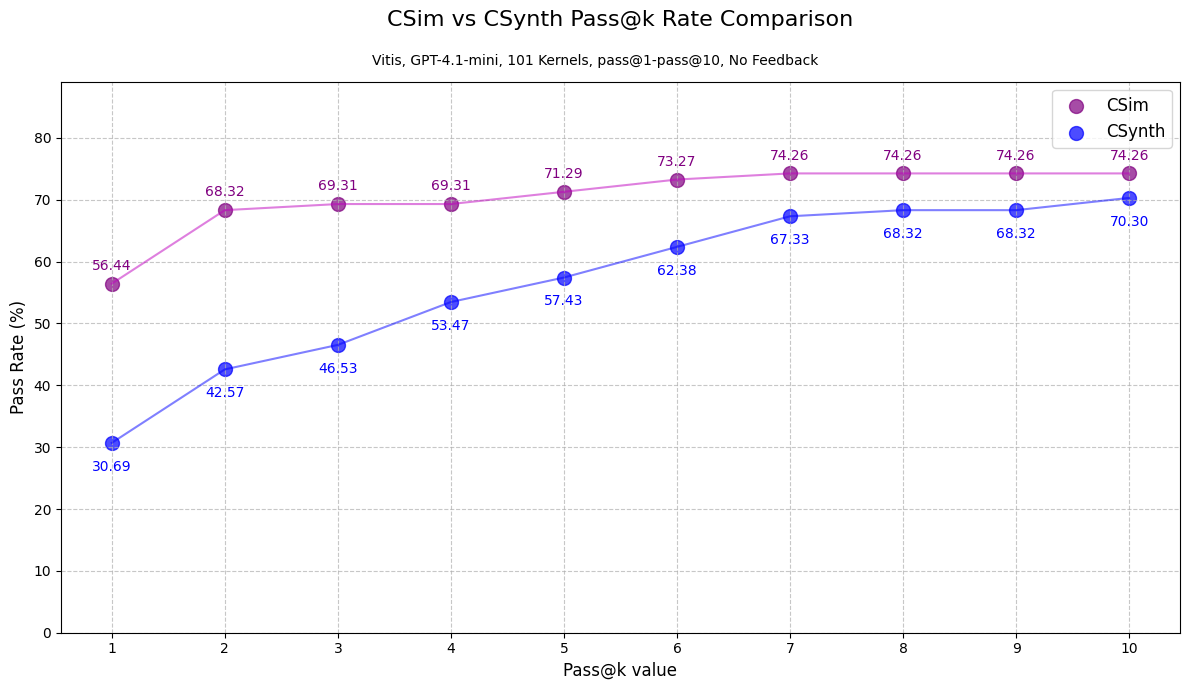

: 

: 

In [ ]:
df_vitis_gpt_41_mini_k10 = pd.read_csv('vitis_gpt-4.1-mini_k10.csv')


# HasDot and HasDCP
k_values = range(1, 11)

csim_rates = calculate_pass_at_k(df_vitis_gpt_41_mini_k10, k_value=10, a_value=1, iter_col1="iteration", iter_col2="attempts", meas="csim")
csynth_rates = calculate_pass_at_k(df_vitis_gpt_41_mini_k10, k_value=10, a_value=1, iter_col1="iteration", iter_col2="attempts", meas="csynth")

csim_rates = np.array(csim_rates)*100
csynth_rates = np.array(csynth_rates)*100
print(csim_rates)
print(csynth_rates)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(k_values, csim_rates, s=100, color='purple', alpha=0.7, label='CSim')
ax.scatter(k_values, csynth_rates, s=100, color='blue', alpha=0.7, label='CSynth')



# Add lines connecting the points
ax.plot(k_values, csim_rates, 'm-', alpha=0.5)
ax.plot(k_values, csynth_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, csim_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(k_values, csynth_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('Pass@k value', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('CSim vs CSynth Pass@k Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_rates) if csim_rates.any() else 0, 
               max(csynth_rates) if csynth_rates.any() else 0)
ax.set_ylim(0, min(100.0, max_rate * 1.20))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis, GPT-4.1-mini, 101 Kernels, pass@1-pass@10, No Feedback', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### Vitis K=1 N=10

[60.3960396  72.27722772 77.22772277 77.22772277 78.21782178 78.21782178
 78.21782178 78.21782178 78.21782178 78.21782178]
[30.69306931 53.46534653 63.36633663 65.34653465 66.33663366 66.33663366
 66.33663366 66.33663366 66.33663366 67.32673267]


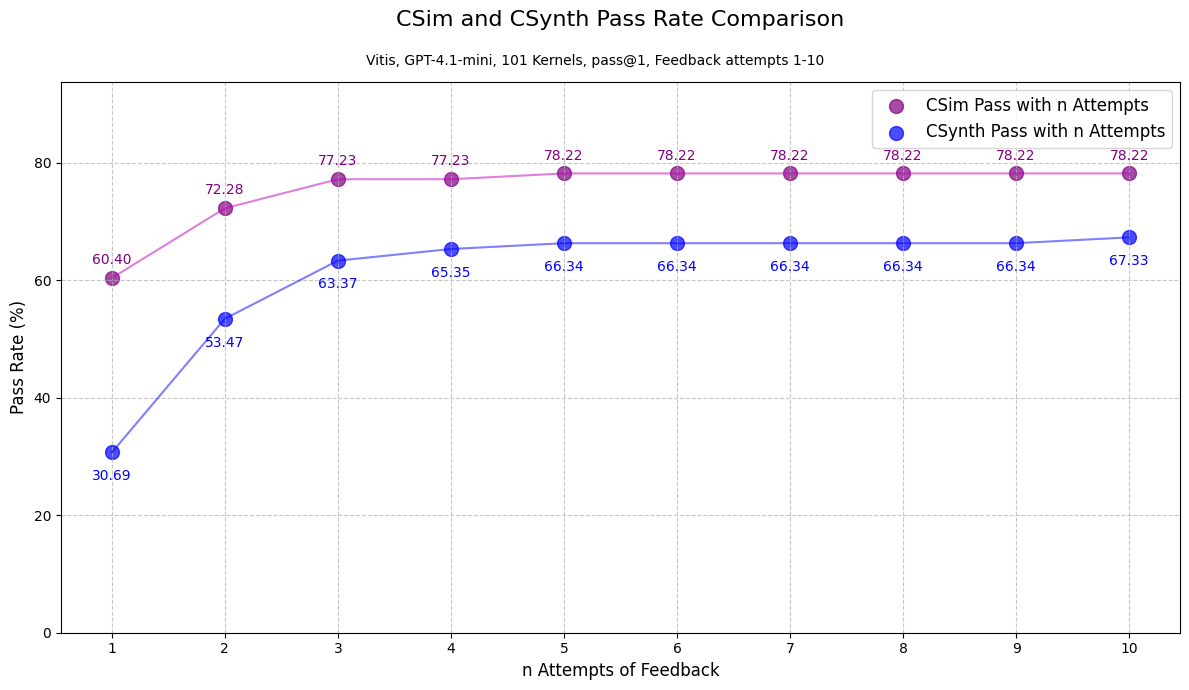

: 

: 

In [ ]:
# HasDot and HasDCP
df_vitis_gpt_41_mini_k1_n10 = pd.read_csv('vitis_gpt-4.1-mini_k1_attempts10.csv')

attempt_values = range(1, 11)


csim_rates = calculate_pass_at_k(df_vitis_gpt_41_mini_k1_n10, k_value=1, a_value=10, iter_col1="iteration", iter_col2="attempts", meas="csim")
csynth_rates = calculate_pass_at_k(df_vitis_gpt_41_mini_k1_n10, k_value=1, a_value=10, iter_col1="iteration", iter_col2="attempts", meas="csynth")

csim_rates = np.array(csim_rates)*100
csynth_rates = np.array(csynth_rates)*100
print(csim_rates)
print(csynth_rates)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(attempt_values, csim_rates, s=100, color='purple', alpha=0.7, label='CSim Pass with n Attempts')
ax.scatter(attempt_values, csynth_rates, s=100, color='blue', alpha=0.7, label='CSynth Pass with n Attempts')

# Add lines connecting the points
ax.plot(attempt_values, csim_rates, 'm-', alpha=0.5)
ax.plot(attempt_values, csynth_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(attempt_values, csim_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(attempt_values, csynth_rates):
    ax.annotate(f'{rate:.2f}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('n Attempts of Feedback', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('CSim and CSynth Pass Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(attempt_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_rates) if csim_rates.any() else 0, 
               max(csynth_rates) if csynth_rates.any() else 0)
ax.set_ylim(0, min(100.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis, GPT-4.1-mini, 101 Kernels, pass@1, Feedback attempts 1-10', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


### Vitis k=3 attempts=3

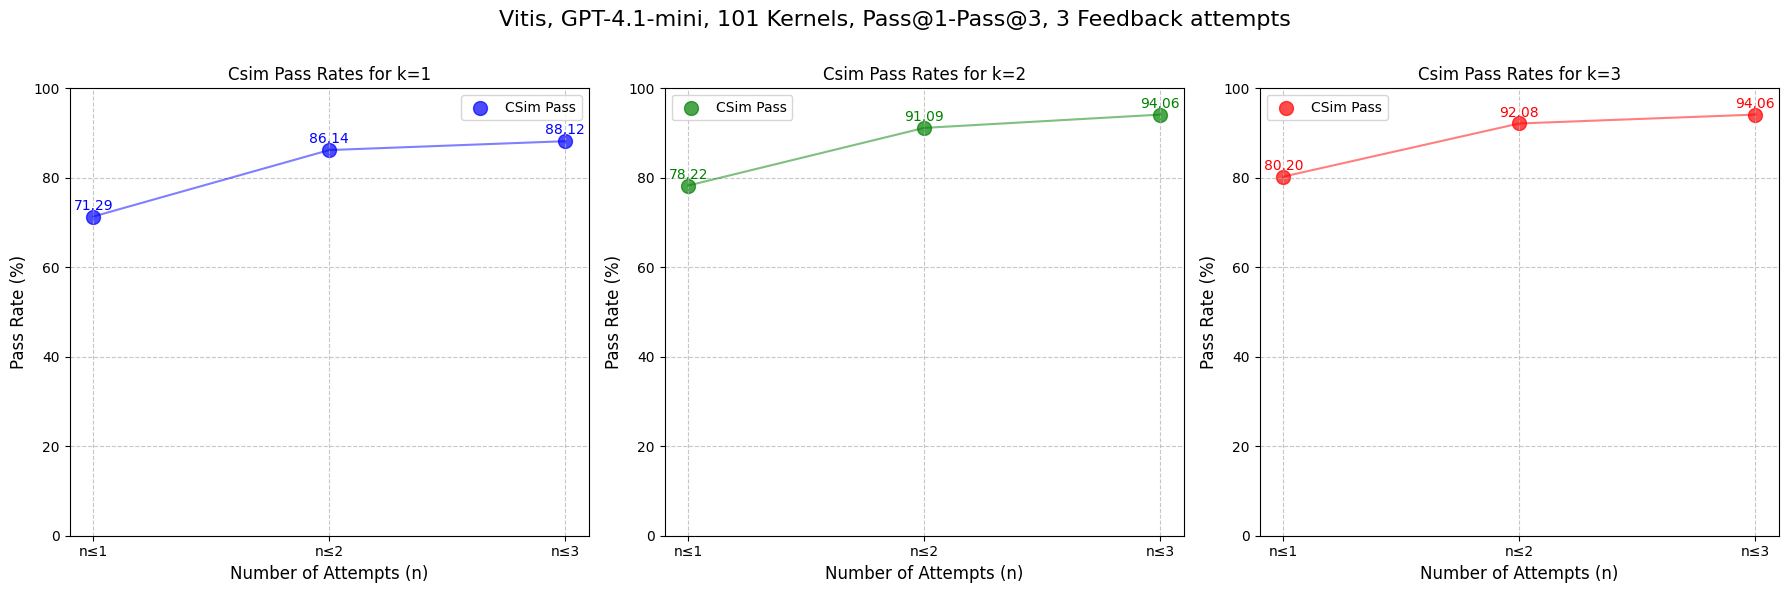

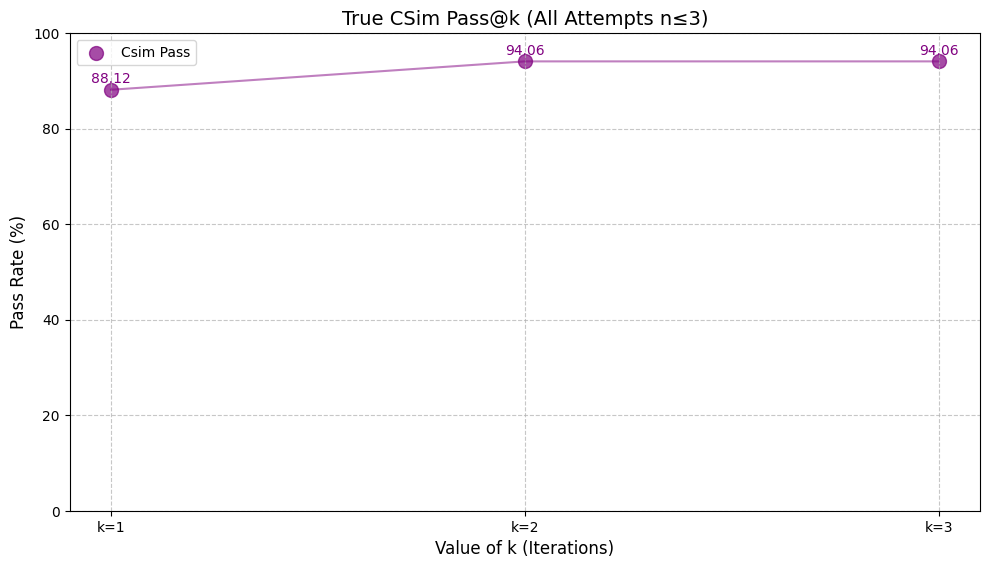

: 

: 

In [ ]:

# Load the data
df_vitis_gpt_41_mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')



csim_rates_k1 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=1, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csim_rates_k2 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=2, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csim_rates_k3 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csim")
csim_rates_k1 = np.array(csim_rates_k1) * 100
csim_rates_k2 = np.array(csim_rates_k2) * 100
csim_rates_k3 = np.array(csim_rates_k3) * 100

# ----- First figure: Three subplots for k=1,2,3 -----
fig1, axes = plt.subplots(1, 3, figsize=(18, 6))

# Common x-axis labels
n_values = [1, 2, 3]
x_labels = [f"n≤{n}" for n in n_values]

# Plot for k=1
ax = axes[0]
ax.scatter(x_labels, csim_rates_k1, s=100, color='blue', alpha=0.7, label='CSim Pass')
ax.plot(x_labels, csim_rates_k1, 'b-', alpha=0.5)
for i, rate in enumerate(csim_rates_k1):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='blue')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Csim Pass Rates for k=1', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=2
ax = axes[1]
ax.scatter(x_labels, csim_rates_k2, s=100, color='green', alpha=0.7, label='CSim Pass')
ax.plot(x_labels, csim_rates_k2, 'g-', alpha=0.5)
for i, rate in enumerate(csim_rates_k2):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='green')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Csim Pass Rates for k=2', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=3
ax = axes[2]
ax.scatter(x_labels, csim_rates_k3, s=100, color='red', alpha=0.7, label='CSim Pass')
ax.plot(x_labels, csim_rates_k3, 'r-', alpha=0.5)
for i, rate in enumerate(csim_rates_k3):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='red')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('Csim Pass Rates for k=3', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Add a title for the first figure
fig1.suptitle('Vitis, GPT-4.1-mini, 101 Kernels, Pass@1-Pass@3, 3 Feedback attempts', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Make room for the suptitle

# ----- Second figure: True pass@k -----
fig2, ax = plt.subplots(figsize=(10, 6))

k_values = [1, 2, 3]
x_labels = [f"k={k}" for k in k_values]

true_pass_at_k_rates = [csim_rates_k1[-1], csim_rates_k2[-1], csim_rates_k3[-1]]

# Plot data for the true pass@k comparison
ax.scatter(x_labels, true_pass_at_k_rates, s=100, color='purple', alpha=0.7, label='Csim Pass')
ax.plot(x_labels, true_pass_at_k_rates, 'purple', alpha=0.5)

# Add labels for each point
for i, rate in enumerate(true_pass_at_k_rates):
    ax.annotate(f'{rate:.2F}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='purple')

# Customize plot
ax.set_xlabel('Value of k (Iterations)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('True CSim Pass@k (All Attempts n≤3)', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# fig2.suptitle('Vitis, GPT-4.1-mini, True CSynth Pass@k Comparison', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.9)  # Make room for the suptitle

# Display all figures
plt.show()
 

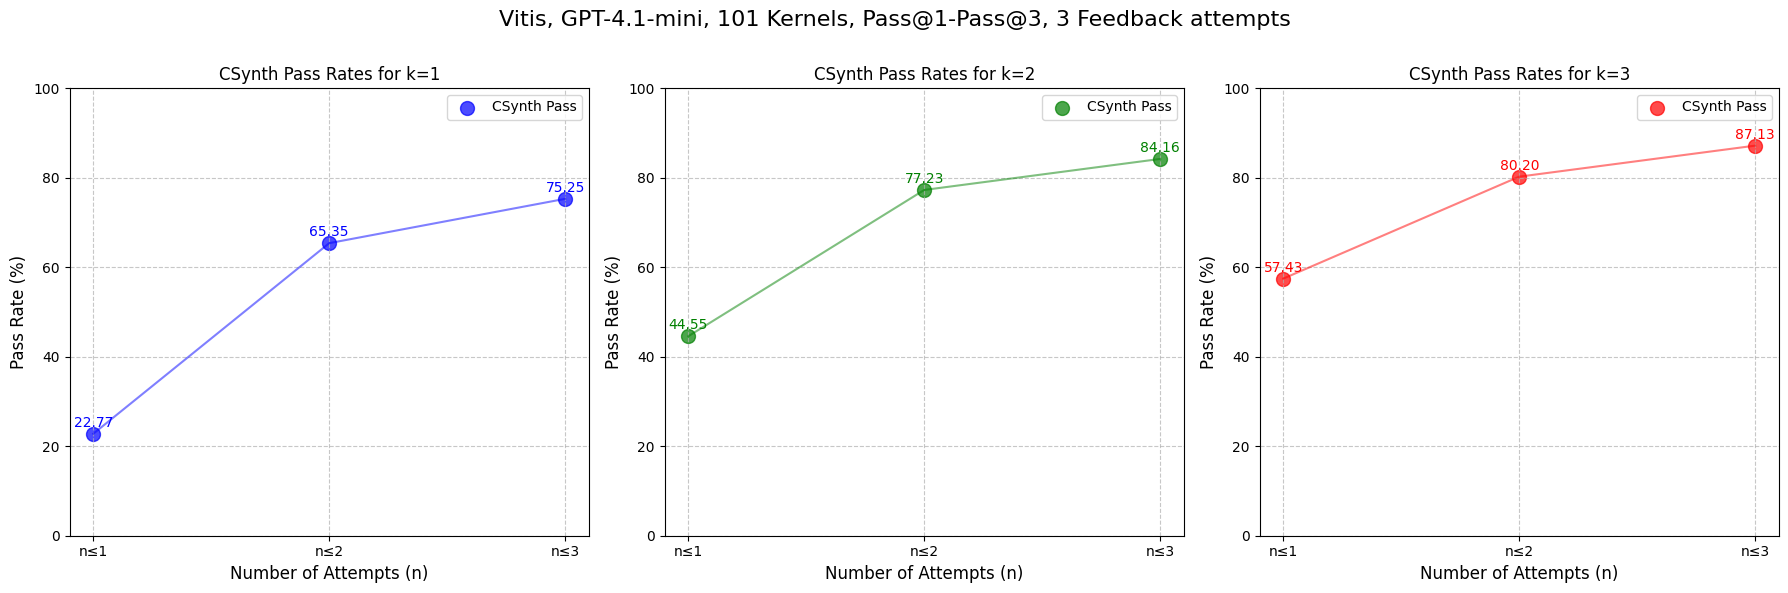

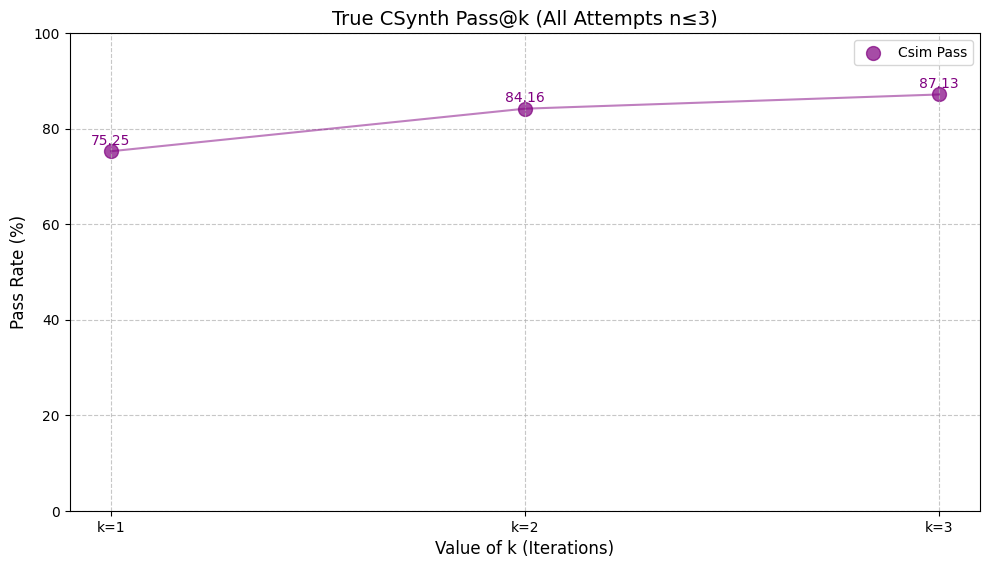

: 

: 

In [ ]:

# Load the data
df_vitis_gpt_41_mini_k3_a3 = pd.read_csv('vitis_gpt-4.1-mini_k3_attempts3.csv')

csim_rates_k1 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=1, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
csim_rates_k2 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=2, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
csim_rates_k3 = calculate_pass_at_k(df_vitis_gpt_41_mini_k3_a3, k_value=3, a_value=3, iter_col1="iteration", iter_col2="attempts", meas="csynth")
csim_rates_k1 = np.array(csim_rates_k1) * 100
csim_rates_k2 = np.array(csim_rates_k2) * 100
csim_rates_k3 = np.array(csim_rates_k3) * 100

# ----- First figure: Three subplots for k=1,2,3 -----
fig1, axes = plt.subplots(1, 3, figsize=(18, 6))

# Common x-axis labels
n_values = [1, 2, 3]
x_labels = [f"n≤{n}" for n in n_values]

# Plot for k=1
ax = axes[0]
ax.scatter(x_labels, csim_rates_k1, s=100, color='blue', alpha=0.7, label='CSynth Pass')
ax.plot(x_labels, csim_rates_k1, 'b-', alpha=0.5)
for i, rate in enumerate(csim_rates_k1):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='blue')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('CSynth Pass Rates for k=1', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=2
ax = axes[1]
ax.scatter(x_labels, csim_rates_k2, s=100, color='green', alpha=0.7, label='CSynth Pass')
ax.plot(x_labels, csim_rates_k2, 'g-', alpha=0.5)
for i, rate in enumerate(csim_rates_k2):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='green')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('CSynth Pass Rates for k=2', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Plot for k=3
ax = axes[2]
ax.scatter(x_labels, csim_rates_k3, s=100, color='red', alpha=0.7, label='CSynth Pass')
ax.plot(x_labels, csim_rates_k3, 'r-', alpha=0.5)
for i, rate in enumerate(csim_rates_k3):
    ax.annotate(f'{rate:.2f}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='red')
ax.set_xlabel('Number of Attempts (n)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('CSynth Pass Rates for k=3', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# Add a title for the first figure
fig1.suptitle('Vitis, GPT-4.1-mini, 101 Kernels, Pass@1-Pass@3, 3 Feedback attempts', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Make room for the suptitle

# ----- Second figure: True pass@k -----
fig2, ax = plt.subplots(figsize=(10, 6))

k_values = [1, 2, 3]
x_labels = [f"k={k}" for k in k_values]

true_pass_at_k_rates = [csim_rates_k1[-1], csim_rates_k2[-1], csim_rates_k3[-1]]

# Plot data for the true pass@k comparison
ax.scatter(x_labels, true_pass_at_k_rates, s=100, color='purple', alpha=0.7, label='Csim Pass')
ax.plot(x_labels, true_pass_at_k_rates, 'purple', alpha=0.5)

# Add labels for each point
for i, rate in enumerate(true_pass_at_k_rates):
    ax.annotate(f'{rate:.2F}', 
               (x_labels[i], rate),
               textcoords="offset points", 
               xytext=(0, 5), 
               ha='center',
               color='purple')

# Customize plot
ax.set_xlabel('Value of k (Iterations)', fontsize=12)
ax.set_ylabel('Pass Rate (%)', fontsize=12)
ax.set_title('True CSynth Pass@k (All Attempts n≤3)', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=10)
ax.set_ylim(0, 100.0)

# fig2.suptitle('Vitis, GPT-4.1-mini, True CSynth Pass@k Comparison', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.9)  # Make room for the suptitle

# Display all figures
plt.show()
 

### Vitis Pie Charts

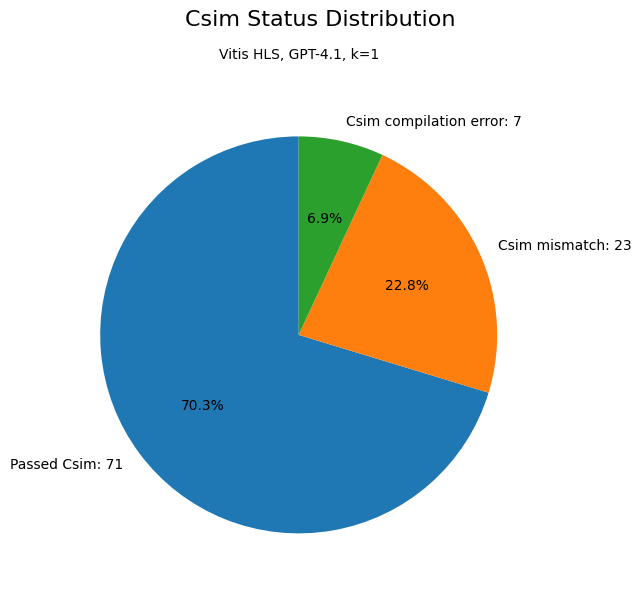

: 

: 

In [ ]:
# Load data
df_vitis_gpt_41_k1 = pd.read_csv('vitis_gpt-4.1_k1.csv')

# Csim pie chart
status_counts = df_vitis_gpt_41_k1['status'].value_counts()
custom_labels = ['Passed Csim', 'Csim mismatch', 'Csim compilation error']

# Create labels with counts directly
labels_with_counts = [f'{label}: {count}' for label, count in zip(custom_labels, status_counts.values)]

fig, ax = plt.subplots(figsize=(7, 6))
ax.pie(
    status_counts.values,
    labels=labels_with_counts,
    autopct='%1.1f%%',
    startangle=90
)

fig.suptitle('Csim Status Distribution', fontsize=16, y=0.98)
plt.title('Vitis HLS, GPT-4.1, k=1', fontsize=10, pad=20)
plt.tight_layout()
plt.show()

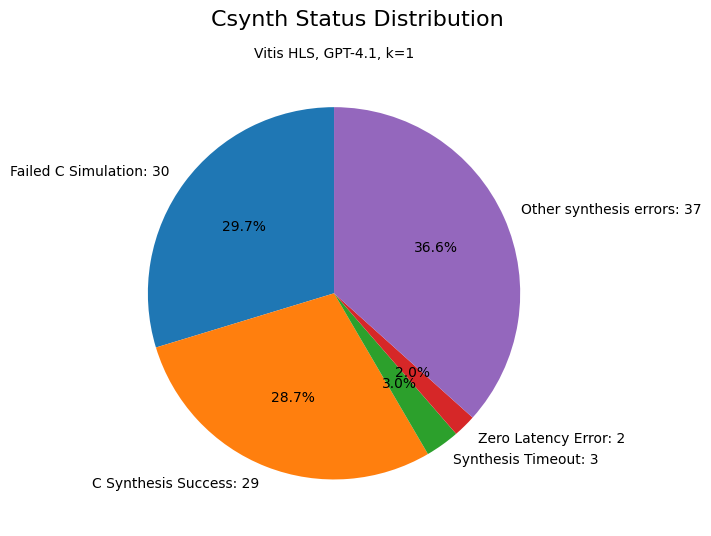

: 

: 

In [ ]:
# Csynth pie chart
import pandas as pd

# Get your value counts
status_counts = df_vitis_gpt_41_k1['synth_errors'].value_counts()

# Define threshold - group categories with only 1 occurrence
threshold = 1
mask = status_counts <= threshold

# Sum the counts of small categories
other_count = status_counts[mask].sum()

# Filter out the small categories
main_counts = status_counts[~mask]

# Add the 'Other' category if there are any small categories
if other_count > 0:
    main_counts['Other'] = other_count

# Create the pie chart
fig, ax = plt.subplots(figsize=(7, 7))

custom_labels = ['Failed C Simulation', 'C Synthesis Success', 'Synthesis Timeout', 'Zero Latency Error', 'Other synthesis errors']

# Create labels with counts
labels_with_counts = [f'{label}: {count}' for label, count in zip(custom_labels, main_counts.values)]

ax.pie(
    main_counts.values,
    labels=labels_with_counts,
    autopct='%1.1f%%',
    startangle=90
)

fig.suptitle('Csynth Status Distribution', fontsize=16, y=0.87)
plt.title('Vitis HLS, GPT-4.1, k=1', fontsize=10, pad=0)
plt.tight_layout()
plt.show()


## Vitis Vision Charts


In [ ]:
vitis_vision_data = {
    "kernel": [ "accumulate_squared_opencv", "rotate_opencv", "sobel_filter_opencv", "auto_exposure_correction_opencv", "bilateral_filter_opencv", "accumulate_weighted_opencv", "accumulate_opencv", "bit_depth_convert_opencv", "add_weighted_opencv", "reduce_avg_opencv"],
    "vitis_vision_latency": [17286, None, 17547, 17587, 20289, 17286, 16901, 16901, 17030, 22328],
    "gpt_4_1_mini_latency": [None, None, None, None, None, 16405, 16401, 16402, 16426, None],
    "claud_sonnet_latency": [16404, None, None, None, None, 16402, 16401, 16401, 16402, None], 
    "gemini_25pro_latency": [2068, None, None, None, None, 16401, 1041, 2066, 1042, None],
    "qwen_3_coder_latency": [16404, None, None, None, 16520, 16401, 16401, 16402, 16420, None], 

    "vitis_vision_bram": [5, 7, 7, 5, 9, 5, 5, 3, 5, 5],
    "gpt_4_1_mini_bram": [None, None, None, None, None, None, None, None, None, None],
    "claud_sonnet_bram": [None, None, None, None, None, None, None, None, None, None],
    "gemini_25pro_bram": [16, None, None, None, None, None, 31, 12, 24, None ],
    "qwen_3_coder_bram": [None, None, None, None, None, None, None, None, None, None],

    "vitis_vision_ff": [6468, 8422, 6630, 9601, 8105, 6605, 6210, 4595, 6995, 11872],
    "gpt_4_1_mini_ff": [None, None, None, None, None, None, None, None, None, None],
    "claud_sonnet_ff": [None, None, None, None, None, None, None, None, None, None],
    "gemini_25pro_ff": [3697, None, None, None, None, None, 3684, 2147, 4127, None],
    "qwen_3_coder_ff": [None, None, None, None, None, None, None, None, None, None],  

    "vitis_vision_lut": [9384, 11132, 9990 ,16665, 12458, 9859, 9140, 6685, 11606, 9330],
    "gpt_4_1_mini_lut": [None, None, None, None, None, None, None, None, None, None],
    "claud_sonnet_lut": [None, None, None, None, None, None, None, None, None, None],
    "gemini_25pro_lut": [3448, None, None, None, None, None, 3753, 4143, 8038, None],
    "qwen_3_coder_lut": [None, None, None, None, None, None, None, None, None, None],
    
    "vitis_vision_dsp": [4, 14, 3, 15, 25, 8, 3, 2, 5, 1],
    "gpt_4_1_mini_dsp": [None, None, None, None, None, None, None, None, None, None],
    "claud_sonnet_dsp": [None, None, None, None, None, None, None, None, None, None],
    "gemini_25pro_dsp": [8, None, None, None, None, None, 0, 0, 73, None],
    "qwen_3_coder_dsp": [None, None, None, None, None, None, None, None, None, None],

}

df = pd.DataFrame(vitis_vision_data)
models=["Vitis Vision", "GPT-4.1 mini", "Claude Sonnet 4", "Gemini 2.5 Pro", "Qwen3 Coder"]

colors = ['blue','dodgerblue','purple','magenta','green']
colors_short = ['blue', 'dodgerblue']

latency_cols = [col for col in df.columns if 'latency' in col or col == 'kernel']
ff_cols = [col for col in df.columns if 'ff' in col or col == 'kernel']
lut_cols = [col for col in df.columns if 'lut' in col or col == 'kernel']
bram_cols = [col for col in df.columns if 'bram' in col or col == 'kernel']
dsp_cols = [col for col in df.columns if 'dsp' in col or col == 'kernel']

: 

: 

IndexError: single positional indexer is out-of-bounds

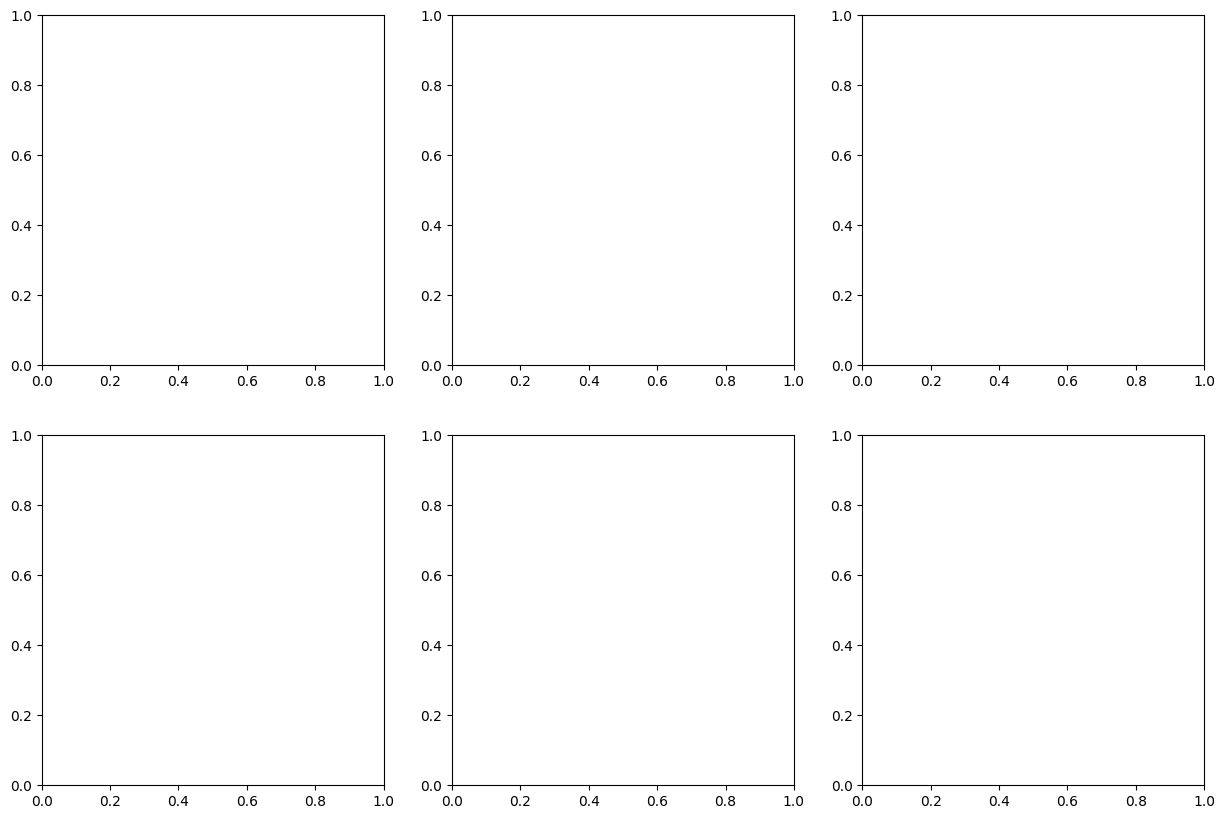

: 

: 

In [ ]:
fig, ax = plt.subplots(2, 3,  figsize=(15,10))


#Accumulate Squared subplot
df_accumulate_squared = df[df["kernel"]=="accumulate_squared_opencv"].iloc[0]
df_latency_accummulate_sqr = df_accumulate_squared[latency_cols]
y_values = df_latency_accummulate_sqr.drop("kernel")
ax[0, 0].bar(models, y_values, width=0.5, color=colors, label='Accumulate Squared')
for y, value in enumerate(y_values):
    print(value)
    ax[0,0].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

#Bilateral filter subplot
df_bilateral = df[df["kernel"]=="bilateral_filter_opencv"].iloc[0]
df_bilateral_latency = df_bilateral[latency_cols]
y_values = df_bilateral_latency.drop("kernel")
ax[0, 1].bar(models, y_values, width=0.5, color=colors, label='Bilateral Filter')
for y, value in enumerate(y_values):
    ax[0, 1].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

#Accumulate Weighted Subplot
df_accumulate_weighted = df[df["kernel"]=="accumulate_weighted_opencv"].iloc[0]
df_accumulate_weighted_latency = df_accumulate_weighted[latency_cols]
y_values = df_accumulate_weighted_latency.drop("kernel")
ax[0, 2].bar(models, y_values, width=0.5, color=colors, label='Accumulate Weighted')
for y, value in enumerate(y_values):
    ax[0,2].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

#Accumulate Subplot
df_accumulate = df[df["kernel"]=="accumulate_opencv"].iloc[0]
df_accumulate_latency = df_accumulate[latency_cols]
y_values = df_accumulate_latency.drop("kernel")
ax[1, 0].bar(models, y_values, width=0.5,  color=colors,label='Accumulate')
for y, value in enumerate(y_values):
    ax[1,0].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

# Bit Depth Subplot
df_bit_depth_convert = df[df["kernel"]=="bit_depth_convert_opencv"].iloc[0]
df_bit_depth_convert_latency = df_bit_depth_convert[latency_cols]
y_values = df_bit_depth_convert_latency.drop("kernel")
ax[1, 1].bar(models, y_values, width=0.5, color=colors, label='Bit Depth Convert')
for y, value in enumerate(y_values):
    ax[1,1].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

# Add Weighted
df_add_weighted = df[df["kernel"]=="add_weighted_opencv"].iloc[0]
df_add_weighted_latency = df_add_weighted[latency_cols]
y_values = df_add_weighted_latency.drop("kernel")
ax[1, 2].bar(models, y_values, width=0.5, color=colors, label='Add Weighted')
for y, value in enumerate(y_values):
    ax[1,2].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])



ax[0,0].tick_params(axis='x', rotation=45)
ax[0,1].tick_params(axis='x', rotation=45)
ax[0,2].tick_params(axis='x', rotation=45)
ax[1,0].tick_params(axis='x', rotation=45)
ax[1,1].tick_params(axis='x', rotation=45)
ax[1,2].tick_params(axis='x', rotation=45)

ax[0,0].set_xlabel('Model', fontsize=10)
ax[0,0].set_ylabel('Latency (Cycles)', fontsize=12)
ax[0,0].set_title('Accumulate Squared', fontsize=12)
ax[0,1].set_xlabel('Model', fontsize=10)
ax[0,1].set_ylabel('Latency (Cycles)', fontsize=12)
ax[0,1].set_title('Bilateral Filter', fontsize=12)
ax[0,2].set_xlabel('Model', fontsize=10)
ax[0,2].set_ylabel('Latency (Cycles)', fontsize=12)
ax[0,2].set_title('Accumulate Weighted', fontsize=12)
ax[1,0].set_xlabel('Model', fontsize=10)
ax[1,0].set_ylabel('Latency (Cycles)', fontsize=12)
ax[1,0].set_title('Accumulate', fontsize=12)
ax[1,1].set_xlabel('Model', fontsize=10)
ax[1,1].set_ylabel('Latency (Cycles)', fontsize=12)
ax[1,1].set_title('Bit Depth Convert', fontsize=12)
ax[1,2].set_xlabel('Model', fontsize=10)
ax[1,2].set_ylabel('Latency (Cycles)', fontsize=12)
ax[1,2].set_title('Add Weighted', fontsize=12)

plt.tight_layout()
plt.show()


['kernel', 'vitis_vision_ff', 'gemini_25pro_ff']
['kernel', 'vitis_vision_ff', 'gemini_25pro_ff']
6468.0
3697.0


/tmp/ipykernel_203266/1877040598.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_values = df_ff_accummulate_sqr.drop("kernel").fillna(1)
/tmp/ipykernel_203266/1877040598.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_values = df_accumulate_ff.drop("kernel").fillna(1)
/tmp/ipykernel_203266/1877040598.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_s

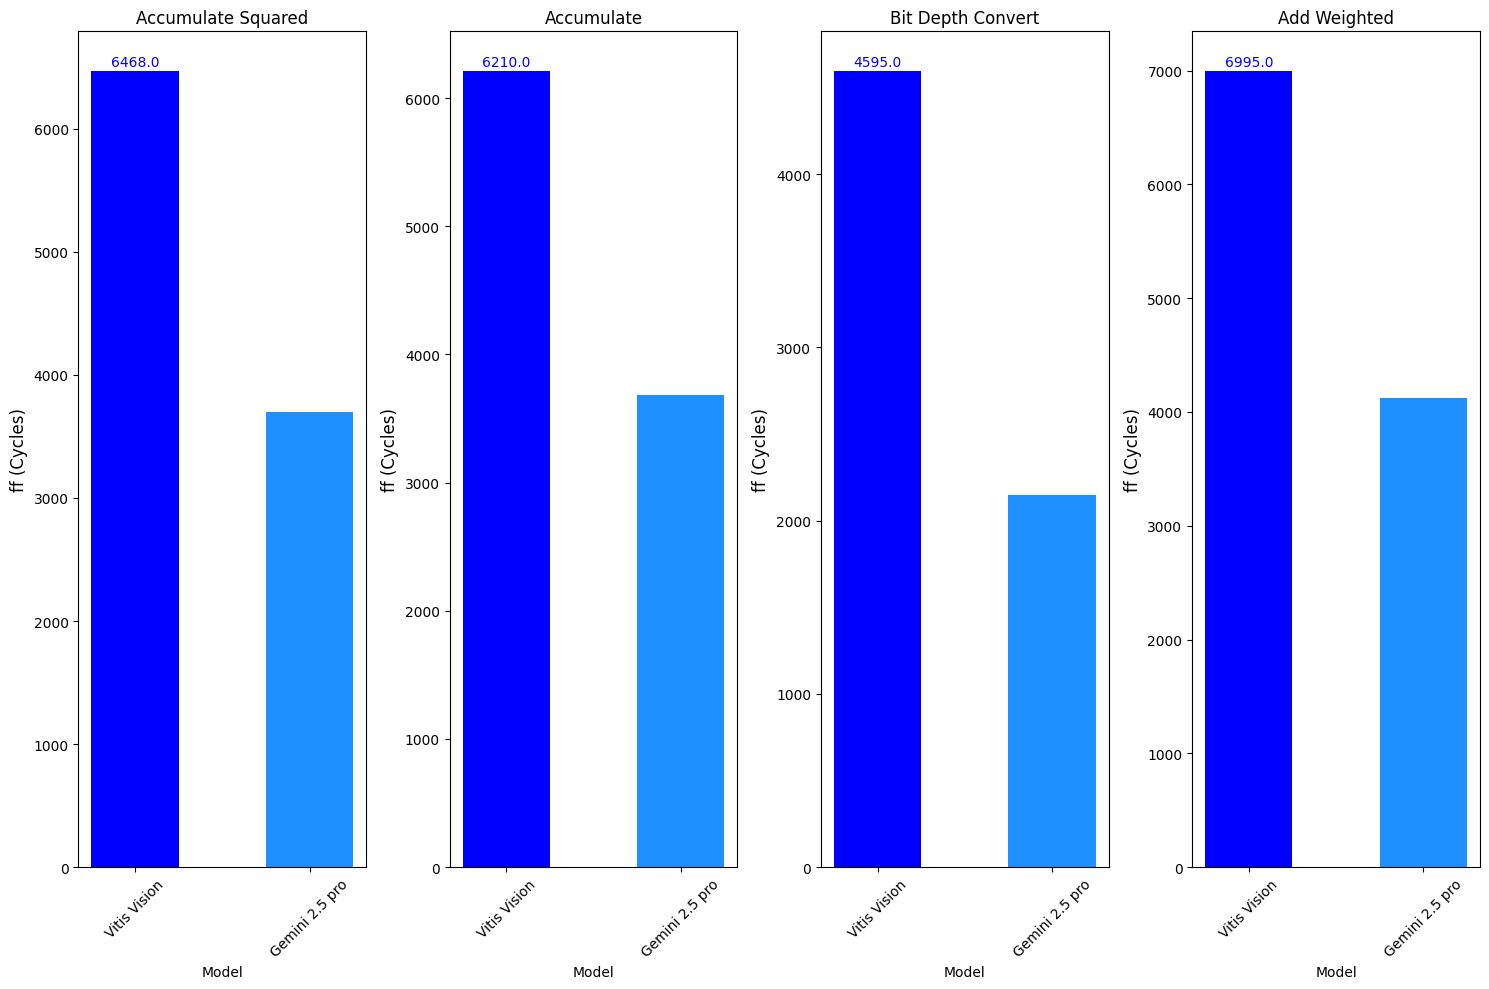

: 

: 

In [ ]:
# FF Graphs Vitis Vision


fig, ax = plt.subplots(1, 4,  figsize=(15,10))

vitis_gemini = ["Vitis Vision", "Gemini 2.5 pro"]
print(ff_cols)
ff_cols = [col for col in ff_cols if "vitis" in col or 'gemini' in col or 'kernel' in col]
print(ff_cols)
#Accumulate Squared subplot
df_accumulate_squared = df[df["kernel"]=="accumulate_squared_opencv"].iloc[0]
df_ff_accummulate_sqr = df_accumulate_squared[ff_cols]
y_values = df_ff_accummulate_sqr.drop("kernel").fillna(1)
ax[0].bar(vitis_gemini, y_values, width=0.5, color=colors, label='Accumulate Squared')
for y, value in enumerate(y_values):
    print(value)
    ax[0].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])


#Accumulate Subplot
df_accumulate = df[df["kernel"]=="accumulate_opencv"].iloc[0]
df_accumulate_ff = df_accumulate[ff_cols]
y_values = df_accumulate_ff.drop("kernel").fillna(1)
ax[1].bar(vitis_gemini, y_values, width=0.5,  color=colors,label='Accumulate')
for y, value in enumerate(y_values):
    ax[1].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

# Bit Depth Subplot
df_bit_depth_convert = df[df["kernel"]=="bit_depth_convert_opencv"].iloc[0]
df_bit_depth_convert_ff = df_bit_depth_convert[ff_cols]
y_values = df_bit_depth_convert_ff.drop("kernel").fillna(1)
ax[2].bar(vitis_gemini, y_values, width=0.5, color=colors, label='Bit Depth Convert')
for y, value in enumerate(y_values):
    ax[2].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])

# Add Weighted
df_add_weighted = df[df["kernel"]=="add_weighted_opencv"].iloc[0]
df_add_weighted_ff = df_add_weighted[ff_cols]
y_values = df_add_weighted_ff.drop("kernel").fillna(1)
ax[3].bar(vitis_gemini, y_values, width=0.5, color=colors, label='Add Weighted')
for y, value in enumerate(y_values):
    ax[3].annotate(f"{value}",
                    (models[y], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[y])



ax[0].tick_params(axis='x', rotation=45)
ax[1].tick_params(axis='x', rotation=45)
ax[2].tick_params(axis='x', rotation=45)
ax[3].tick_params(axis='x', rotation=45)


ax[0].set_xlabel('Model', fontsize=10)
ax[0].set_ylabel('ff (Cycles)', fontsize=12)
ax[0].set_title('Accumulate Squared', fontsize=12)
ax[1].set_xlabel('Model', fontsize=10)
ax[1].set_ylabel('ff (Cycles)', fontsize=12)
ax[1].set_title('Accumulate', fontsize=12)
ax[2].set_xlabel('Model', fontsize=10)
ax[2].set_ylabel('ff (Cycles)', fontsize=12)
ax[2].set_title('Bit Depth Convert', fontsize=12)
ax[3].set_xlabel('Model', fontsize=10)
ax[3].set_ylabel('ff (Cycles)', fontsize=12)
ax[3].set_title('Add Weighted', fontsize=12)

plt.tight_layout()
plt.show()

## Vitis One Shot k=1 n=1

[0.0]


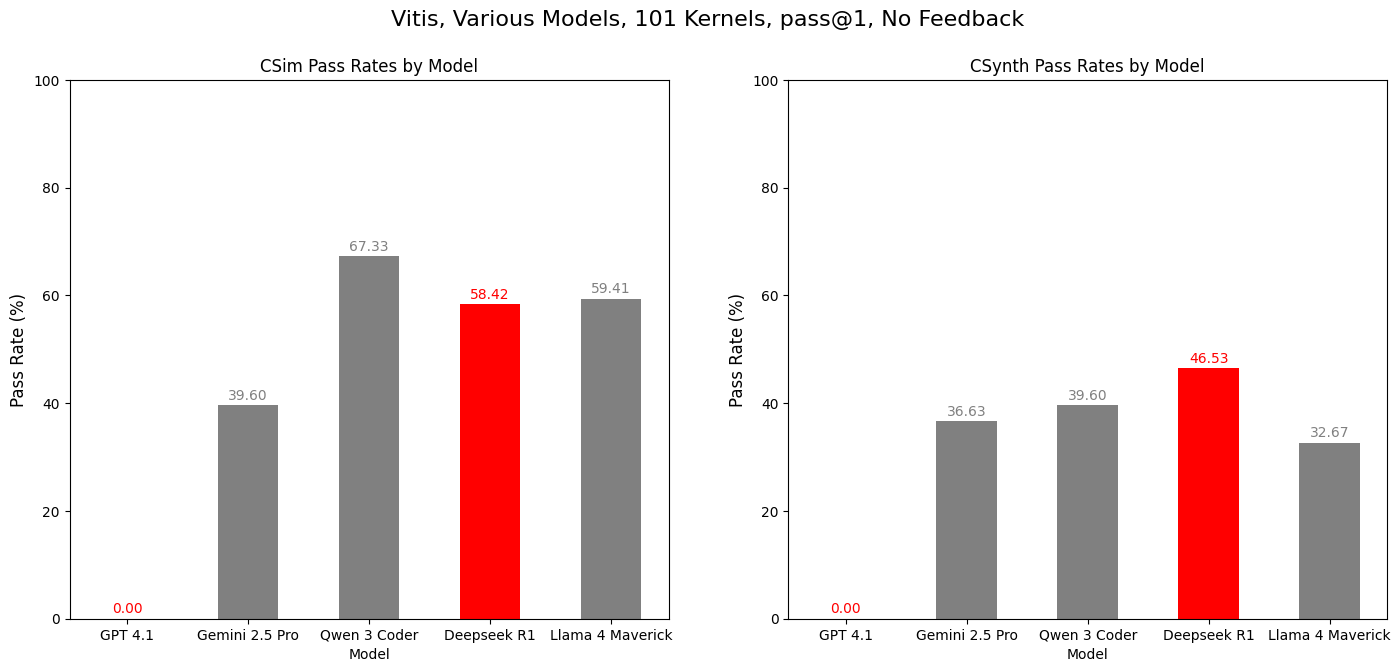

: 

: 

In [ ]:
### Looking at the oneshot results from the following LLMs
# Gemini 2.5 pro
# Qwen 3 coder
# Deepseek r1
# Llama 4 maverick

df1 = pd.read_csv("vitis_oneshot_k1n1.csv")
df2 = pd.read_csv("vitis_gpt-4.1_k1.csv")
df = pd.concat([df1,df2])
# print(df)

fig, ax = plt.subplots(1, 2, figsize=(17,7))
fig.suptitle("Vitis, Various Models, 101 Kernels, pass@1, No Feedback", fontsize=16)

gemini_pass_rate = calculate_pass_at_k(df, meas="csim", model="gemini-2.5-pro")
qwen_pass_rate = calculate_pass_at_k(df, meas="csim", model="qwen3-coder")
deepseek_pass_rate = calculate_pass_at_k(df, meas="csim", model="deepseek-r1")
llama_pass_rate = calculate_pass_at_k(df, meas="csim", model="llama-4-maverick")
gpt_pass_rate = calculate_pass_at_k(df, meas="csim", model="gpt-4.1")
print(gpt_pass_rate)

passing_rates = [gpt_pass_rate[0], gemini_pass_rate[0], qwen_pass_rate[0], deepseek_pass_rate[0], llama_pass_rate[0]]
passing_rates = np.array(passing_rates) * 100
models = ["GPT 4.1", "Gemini 2.5 Pro", "Qwen 3 Coder", "Deepseek R1", "Llama 4 Maverick"]

ax[0].bar(models, passing_rates, width=0.5, color=colors, label="CSIM Pass Rates")
ax[0].set_xlabel('Model', fontsize=10)
ax[0].set_ylabel('Pass Rate (%)', fontsize=12)
ax[0].set_title('CSim Pass Rates by Model', fontsize=12)
ax[0].set_ylim(0, 100)

for c, value in enumerate(passing_rates):
    ax[0].annotate(f"{value:.2f}",
                    (models[c], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[c])


gemini_pass_rate = calculate_pass_at_k(df, meas="csynth", model="gemini-2.5-pro")
qwen_pass_rate = calculate_pass_at_k(df, meas="csynth", model="qwen3-coder")
deepseek_pass_rate = calculate_pass_at_k(df, meas="csynth", model="deepseek-r1")
llama_pass_rate = calculate_pass_at_k(df, meas="csynth", model="llama-4-maverick")
gpt_pass_rate = calculate_pass_at_k(df, meas="csynth", model="gpt-4.1")


passing_rates = [gpt_pass_rate[0], gemini_pass_rate[0], qwen_pass_rate[0], deepseek_pass_rate[0], llama_pass_rate[0]]
passing_rates = np.array(passing_rates) * 100

models = ["GPT 4.1", "Gemini 2.5 Pro", "Qwen 3 Coder", "Deepseek R1", "Llama 4 Maverick"]

ax[1].bar(models, passing_rates, width=0.5, color=colors, label="CSynth Pass Rates")
ax[1].set_xlabel('Model', fontsize=10)
ax[1].set_ylabel('Pass Rate (%)', fontsize=12)
ax[1].set_title('CSynth Pass Rates by Model', fontsize=12)
ax[1].set_ylim(0, 100)

for c, value in enumerate(passing_rates):
    ax[1].annotate(f"{value:.2f}",
                    (models[c], value),
                    textcoords="offset points", 
                    xytext=(0, 4), 
                    ha='center',
                    color=colors[c])

plt.show()

: 

: 

: 

: 